# Code Ownership, notebook 6: the final test (once) and the production artifact

The chosen model is refit on all development functions (settings chosen by inner grouped folds over the development set) and scored **once** on the 6 final-test functions.
Then it is refit on all 36 functions for the artifact the agent loads. The test result comes only from the development-fit model.

In [1]:
import sys, warnings, json, pickle
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("../../helpers").resolve()))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
import ko_data as K, ko_models as M
from core import metrics, group_bootstrap, paired_diff_bootstrap, qwk, band
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
d = K.load()
dev = d[d.role == "dev"].reset_index(drop=True)
test = d[d.role == "test"].reset_index(drop=True)
y, groups, folds = dev.score.to_numpy(), dev.snippet_id.to_numpy(), dev.fold.to_numpy()
def ci(p, stat):
    return group_bootstrap(y, p, groups, stat, n=1000)
def sp(a, b):
    return spearmanr(a, b).correlation
def mae(a, b):
    return float(np.mean(np.abs(a - b)))
def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

In [2]:
import joblib
choice = json.loads((RESULTS / "model_choice.json").read_text(encoding="utf-8"))
prod = choice["production"]
print(prod)
Hd, Ht = K.hand_features(dev), K.hand_features(test)
if prod["kind"] == "encoder":
    Xd = K.feature_sets(K.embeddings(prod["encoder"], dev), Hd)[prod["feature_set"]]
    Xt = K.feature_sets(K.embeddings(prod["encoder"], test), Ht)[prod["feature_set"]]
else:
    Xd, Xt = Hd.to_numpy(float), Ht.to_numpy(float)
Xd, Xt = np.asarray(Xd, float), np.asarray(Xt, float)
head = prod["head"]
NH = Hd.shape[1] if prod["feature_set"].endswith("+H") else 0
from concurrent.futures import ProcessPoolExecutor
with ProcessPoolExecutor(10) as pool:
    params, _ = M.tune_one(head, Xd, y, groups, 0, pool, NH)
print("settings chosen on the development set:", params)
pt = M.fit_predict(head, params, Xd, y, Xt, 0)
yt = test.score.to_numpy()

{'kind': 'encoder', 'key': 'codebert|B+H|svr', 'encoder': 'codebert', 'feature_set': 'B+H', 'head': 'svr'}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12423.96it/s]

settings chosen on the development set: {'C': 10, 'epsilon': 0.05, 'gamma': 0.0001, 'n_hand': 12, 'hw': 20}


In [3]:
tg = test.snippet_id.to_numpy()
def tci(stat):
    return group_bootstrap(yt, pt, tg, stat, n=2000)
m = metrics(yt, pt)
res = {"n answers": len(yt), "n functions": len(set(tg)), "MAE": m["MAE"], "RMSE": m["RMSE"], "Spearman": m["spearman"], "Pearson": m["pearson"], "QWK (1-5 bands)": m["band_qwk"], "ICC(2,1)": m["ICC2_1"]}
print({k: round(v, 3) for k, v in res.items()})
print("95% intervals (grouped bootstrap over the 6 functions): MAE", np.round(tci(mae), 3), "Spearman", np.round(tci(lambda a, b: sp(a, b)), 3))

{'n answers': 38, 'n functions': 6, 'MAE': 0.137, 'RMSE': 0.175, 'Spearman': 0.882, 'Pearson': 0.885, 'QWK (1-5 bands)': 0.841, 'ICC(2,1)': 0.852}


95% intervals (grouped bootstrap over the 6 functions): MAE [0.102 0.168] Spearman [0.824 0.936]


In [4]:
# the same baselines, fitted on the development functions only, scored on the same test answers
from sklearn.linear_model import LinearRegression
rows = [{"model": "production model", "MAE": mae(pt, yt), "Spearman": sp(pt, yt)}, {"model": "training mean", "MAE": mae(np.full(len(yt), y.mean()), yt), "Spearman": float("nan")}]
for col, name in (("n_words", "answer length"), ("identifier_recall", "identifier recall"), ("focus_overlap", "overlap with the asked-about fact")):
    lr = LinearRegression().fit(Hd[[col]], y); p = np.clip(lr.predict(Ht[[col]]), 0, 1)
    rows.append({"model": name, "MAE": mae(p, yt), "Spearman": sp(p, yt)})
pd.DataFrame(rows).round(3)

,model,MAE,Spearman
0,production model,0.137,0.882
1,training mean,0.305,NaN
2,answer length,0.294,0.596
3,identifier recall,0.300,0.368
4,overlap with the asked-about fact,0.309,0.208


               n    MAE
question_type          
early_return   5  0.057
guard          7  0.157
handler        7  0.087
loop           7  0.157
purpose        7  0.189
return_value   5  0.154


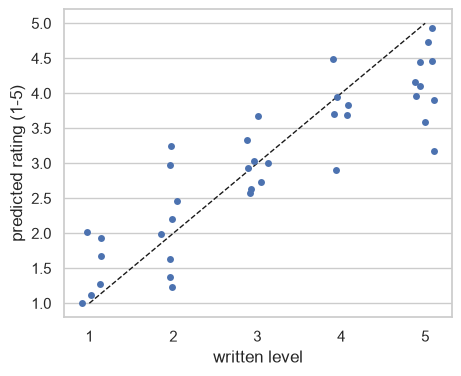

In [5]:
t2 = test.assign(pred=pt, err=np.abs(pt - yt))
print(t2.groupby("question_type").agg(n=("err", "size"), MAE=("err", "mean")).round(3))
fig, ax = plt.subplots(figsize=(5, 4)); sns.stripplot(data=t2, x="rating", y=1 + 4 * t2.pred, ax=ax, jitter=0.15); ax.plot([0, 4], [1, 5], "k--", lw=1); ax.set_ylabel("predicted rating (1-5)"); ax.set_xlabel("written level"); plt.show()

Sensitivity to the label: the same predictions against the independent rating and against the mean of the two ratings.

In [6]:
out = {}
for col in ("score", "score_independent", "score_mean"):
    yy = test[col].to_numpy(); out[col] = {"MAE": mae(pt, yy), "Spearman": sp(pt, yy)}
pd.DataFrame(out).T.round(3)

,MAE,Spearman
score,0.137,0.882
score_independent,0.179,0.825
score_mean,0.156,0.873


## Production artifact

Refit on all 36 functions (settings chosen on all of them), plus the 10th and 90th percentile of the development out-of-fold residuals as the reported band.

In [7]:
allX = np.vstack([Xd, Xt]); ally = np.concatenate([y, yt]); allg = np.concatenate([groups, tg])
with ProcessPoolExecutor(10) as pool:
    params_all, _ = M.tune_one(head, allX, ally, allg, 0, pool, NH)
final = M.make(head, params_all, 0).fit(allX, ally)
P = pickle.load(open(RESULTS / "tuning_preds.pkl", "rb"))
B = pickle.load(open(RESULTS / "baselines_oof.pkl", "rb"))
oof = P[choice["encoder_model"]]["pred"] if prod["kind"] == "encoder" else B[prod["key"]]
resid = y - oof
MODEL = Path("../../../model").resolve(); MODEL.mkdir(exist_ok=True)
joblib.dump(final, MODEL / "ko_head.joblib")
card = {"encoder": prod["encoder"], "feature_set": prod["feature_set"], "head": head, "params": params_all, "features_version": "ko_features/2",
        "trained_on": "36 standard-library functions, 216 assistant-written answers (no student data, no human ratings)",
        "dev_oof": {"MAE": mae(oof, y), "Spearman": sp(oof, y)}, "final_test": {k: float(v) for k, v in res.items()},
        "residual_quantiles": [float(np.percentile(resid, 10)), float(np.percentile(resid, 90))]}
(MODEL / "ko_model.json").write_text(json.dumps(card, indent=1), encoding="utf-8")
card

{'encoder': 'codebert',
 'feature_set': 'B+H',
 'head': 'svr',
 'params': {'C': 3, 'epsilon': 0.05, 'gamma': 0.0001, 'n_hand': 12, 'hw': 20},
 'features_version': 'ko_features/2',
 'trained_on': '36 standard-library functions, 216 assistant-written answers (no student data, no human ratings)',
 'dev_oof': {'MAE': 0.1614402494171667,
  'Spearman': np.float64(0.8117135657156519)},
 'final_test': {'n answers': 38.0,
  'n functions': 6.0,
  'MAE': 0.13662838034160282,
  'RMSE': 0.1751575461984347,
  'Spearman': 0.8823501508263292,
  'Pearson': 0.8853879877156594,
  'QWK (1-5 bands)': 0.8412698412698413,
  'ICC(2,1)': 0.8520731322597793},
 'residual_quantiles': [-0.2832050411824714, 0.2772137513976272]}

## Reading the results

**Final test (6 functions, 38 answers, scored once).** MAE 0.137 (95% interval over the 6 functions 0.102 to 0.168), RMSE 0.175, Spearman 0.88 (0.82 to 0.94), Pearson 0.89, QWK on 1 to 5 bands 0.84, ICC(2,1) 0.85. On the same answers: predicting the mean MAE 0.305; answer length 0.294 (Spearman 0.60); identifier recall 0.300; overlap with the asked-about fact 0.309. The error is similar for every question type (MAE 0.06 to 0.19; the smallest for early returns and handlers, the largest for the "what does it do" question).

**Against the other labels.** The same predictions against the independent rating: MAE 0.179, Spearman 0.83; against the mean of the two ratings: 0.156 and 0.87.

**How to read it.** The development estimate (MAE 0.161, Spearman 0.81) and the test (0.137, 0.88) agree within their intervals, which are wide with only 6 functions. These are results on answers written by the assistant in one style, about polished library code, in Python: they show the pipeline separates answers written at different levels of understanding, not that it agrees with human graders on real student answers about application code. The proposal's reference point is a fine-tuned encoder at 0.80 to 0.81 correlation with human graders (Oli et al.); the 0.88 here is not comparable to it. The artifact in `model/` is refit on all 36 functions.
